# Классификация ядовитых грибов

Сравнение классического градиентного бустинга и CatBoost на категориальных табличных данных. Основная метрика — Recall ядовитого класса; Precision и матрица ошибок показывают цену увеличения полноты.

Исследование включает EDA, подготовку признаков, базовую модель, подбор гиперпараметров по кросс-валидации, анализ порогов и важность признаков. Обучение проводится на 80% объектов; validation и test занимают по 10%. Ядовитому классу соответствует метка 1.

Для запуска установите зависимости из `requirements.txt` и поместите `mushrooms.csv` в папку `data`. Запускайте ноутбук из папки проекта. Метрики относятся к данному набору и разбиению; модель не предназначена для решения о безопасности употребления реальных грибов.


In [2]:
# Библиотеки для анализа данных и моделирования

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

from catboost import CatBoostClassifier

pd.set_option("display.max_columns", 500)
pd.set_option("display.max_colwidth", 10000)

## 1. Загрузка и первичный анализ

Проверим структуру данных, типы признаков, пропуски и дубликаты.

In [3]:
from pathlib import Path

data_path = Path('data/mushrooms.csv')
if not data_path.exists():
    raise FileNotFoundError('Поместите mushrooms.csv в папку data и запустите ноутбук из папки проекта.')
df_work = pd.read_csv(data_path)
df = df_work.copy()

In [4]:
df.head(10)

,cap-texture,spore-pattern,stem-flexibility,ring-thickness,cap-shape,cap-surface,cap-color,gill-attachment,stalk-shape,veil-type,veil-color,ring-number,population,habitat,class
0,j,i,a,a,x,s,n,f,e,p,w,o,s,u,p
1,m,g,f,c,x,s,y,f,e,p,w,o,n,g,e
2,m,c,e,a,b,s,w,f,e,p,w,o,n,m,e
3,e,i,j,b,x,y,w,f,e,p,w,o,s,u,p
4,b,i,h,b,x,s,g,f,t,p,w,o,a,g,e
5,e,f,h,c,x,y,y,f,e,p,w,o,n,g,e
6,h,a,c,c,b,s,w,f,e,p,w,o,n,m,e
7,b,j,e,a,b,y,w,f,e,p,w,o,s,m,e
8,p,d,j,c,x,y,w,f,e,p,w,o,v,g,p
9,n,m,c,c,b,s,y,f,e,p,w,o,s,m,e


In [5]:
df.shape

(8124, 15)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   cap-texture       8124 non-null   str  
 1   spore-pattern     8124 non-null   str  
 2   stem-flexibility  8124 non-null   str  
 3   ring-thickness    8124 non-null   str  
 4   cap-shape         8124 non-null   str  
 5   cap-surface       8124 non-null   str  
 6   cap-color         8124 non-null   str  
 7   gill-attachment   8124 non-null   str  
 8   stalk-shape       8124 non-null   str  
 9   veil-type         8124 non-null   str  
 10  veil-color        8124 non-null   str  
 11  ring-number       8124 non-null   str  
 12  population        8124 non-null   str  
 13  habitat           8124 non-null   str  
 14  class             8124 non-null   str  
dtypes: str(15)
memory usage: 952.2 KB


In [7]:
df.isna().sum()

cap-texture         0
spore-pattern       0
stem-flexibility    0
ring-thickness      0
cap-shape           0
cap-surface         0
cap-color           0
gill-attachment     0
stalk-shape         0
veil-type           0
veil-color          0
ring-number         0
population          0
habitat             0
class               0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

> Датасет содержит 8 124 строки и 15 столбцов, один из которых — целевая переменная `class`. Все столбцы имеют тип `object` и содержат категориальные значения.
>
> Явных пропусков `NaN` и полных дубликатов строк не обнаружено, поэтому на этом этапе удалять или заполнять данные не потребовалось. При дальнейшем исследовании категорий необходимо проверить, нет ли скрытых пропусков, записанных специальными символами.

## 2. Категориальные признаки и качество данных

Исследуем значения и распределения категорий, скрытые пропуски, константные признаки и баланс классов.

In [9]:
df.nunique()

cap-texture         19
spore-pattern       15
stem-flexibility    10
ring-thickness       3
cap-shape            6
cap-surface          4
cap-color           10
gill-attachment      2
stalk-shape          2
veil-type            1
veil-color           4
ring-number          4
population           6
habitat              7
class                2
dtype: int64

In [10]:
df.describe()

,cap-texture,spore-pattern,stem-flexibility,ring-thickness,cap-shape,cap-surface,cap-color,gill-attachment,stalk-shape,veil-type,veil-color,ring-number,population,habitat,class
count,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124
unique,19,15,10,3,6,4,10,2,2,1,4,4,6,7,2
top,a,o,i,c,x,y,n,f,t,p,w,o,v,d,e
freq,435,548,820,2723,3656,3244,2284,7914,4608,8124,7924,7487,4040,3148,4208


In [11]:
df.drop(columns=['veil-type'], inplace=True)

/var/folders/7b/8lm37ffs6_l39j9b27jt7scc0000gn/T/ipykernel_10001/875754692.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['veil-type'], inplace=True)


In [12]:
df[df['ring-number'] == '?']

,cap-texture,spore-pattern,stem-flexibility,ring-thickness,cap-shape,cap-surface,cap-color,gill-attachment,stalk-shape,veil-color,ring-number,population,habitat,class
105,k,d,i,a,x,y,y,f,e,w,?,n,m,e


In [13]:
markers = ['?', '', 'unknown', 'NA', 'null']

marker_counts = df.isin(markers).sum()
print(marker_counts[marker_counts > 0])

ring-number    1
dtype: int64


In [14]:
df['ring-number'] = df['ring-number'].replace('?', np.nan)

In [15]:
df.isna().sum()

cap-texture         0
spore-pattern       0
stem-flexibility    0
ring-thickness      0
cap-shape           0
cap-surface         0
cap-color           0
gill-attachment     0
stalk-shape         0
veil-color          0
ring-number         1
population          0
habitat             0
class               0
dtype: int64

In [16]:
for column in df.columns:
    print(f'{column}: {df[column].unique()}')

cap-texture: <StringArray>
['j', 'm', 'e', 'b', 'h', 'p', 'n', 'a', 'l', 'g', 'r', 's', 'f', 'i', 'd',
 'k', 'c', 'q', 'o']
Length: 19, dtype: str
spore-pattern: <StringArray>
['i', 'g', 'c', 'f', 'a', 'j', 'd', 'm', 'o', 'e', 'b', 'n', 'h', 'l', 'k']
Length: 15, dtype: str
stem-flexibility: <StringArray>
['a', 'f', 'e', 'j', 'h', 'c', 'b', 'i', 'g', 'd']
Length: 10, dtype: str
ring-thickness: <StringArray>
['a', 'c', 'b']
Length: 3, dtype: str
cap-shape: <StringArray>
['x', 'b', 's', 'f', 'k', 'c']
Length: 6, dtype: str
cap-surface: <StringArray>
['s', 'y', 'f', 'g']
Length: 4, dtype: str
cap-color: <StringArray>
['n', 'y', 'w', 'g', 'e', 'p', 'b', 'u', 'c', 'r']
Length: 10, dtype: str
gill-attachment: <StringArray>
['f', 'a']
Length: 2, dtype: str
stalk-shape: <StringArray>
['e', 't']
Length: 2, dtype: str
veil-color: <StringArray>
['w', 'n', 'o', 'y']
Length: 4, dtype: str
ring-number: <StringArray>
['o', nan, 't', 'n']
Length: 4, dtype: str
population: <StringArray>
['s', 'n', 'a',

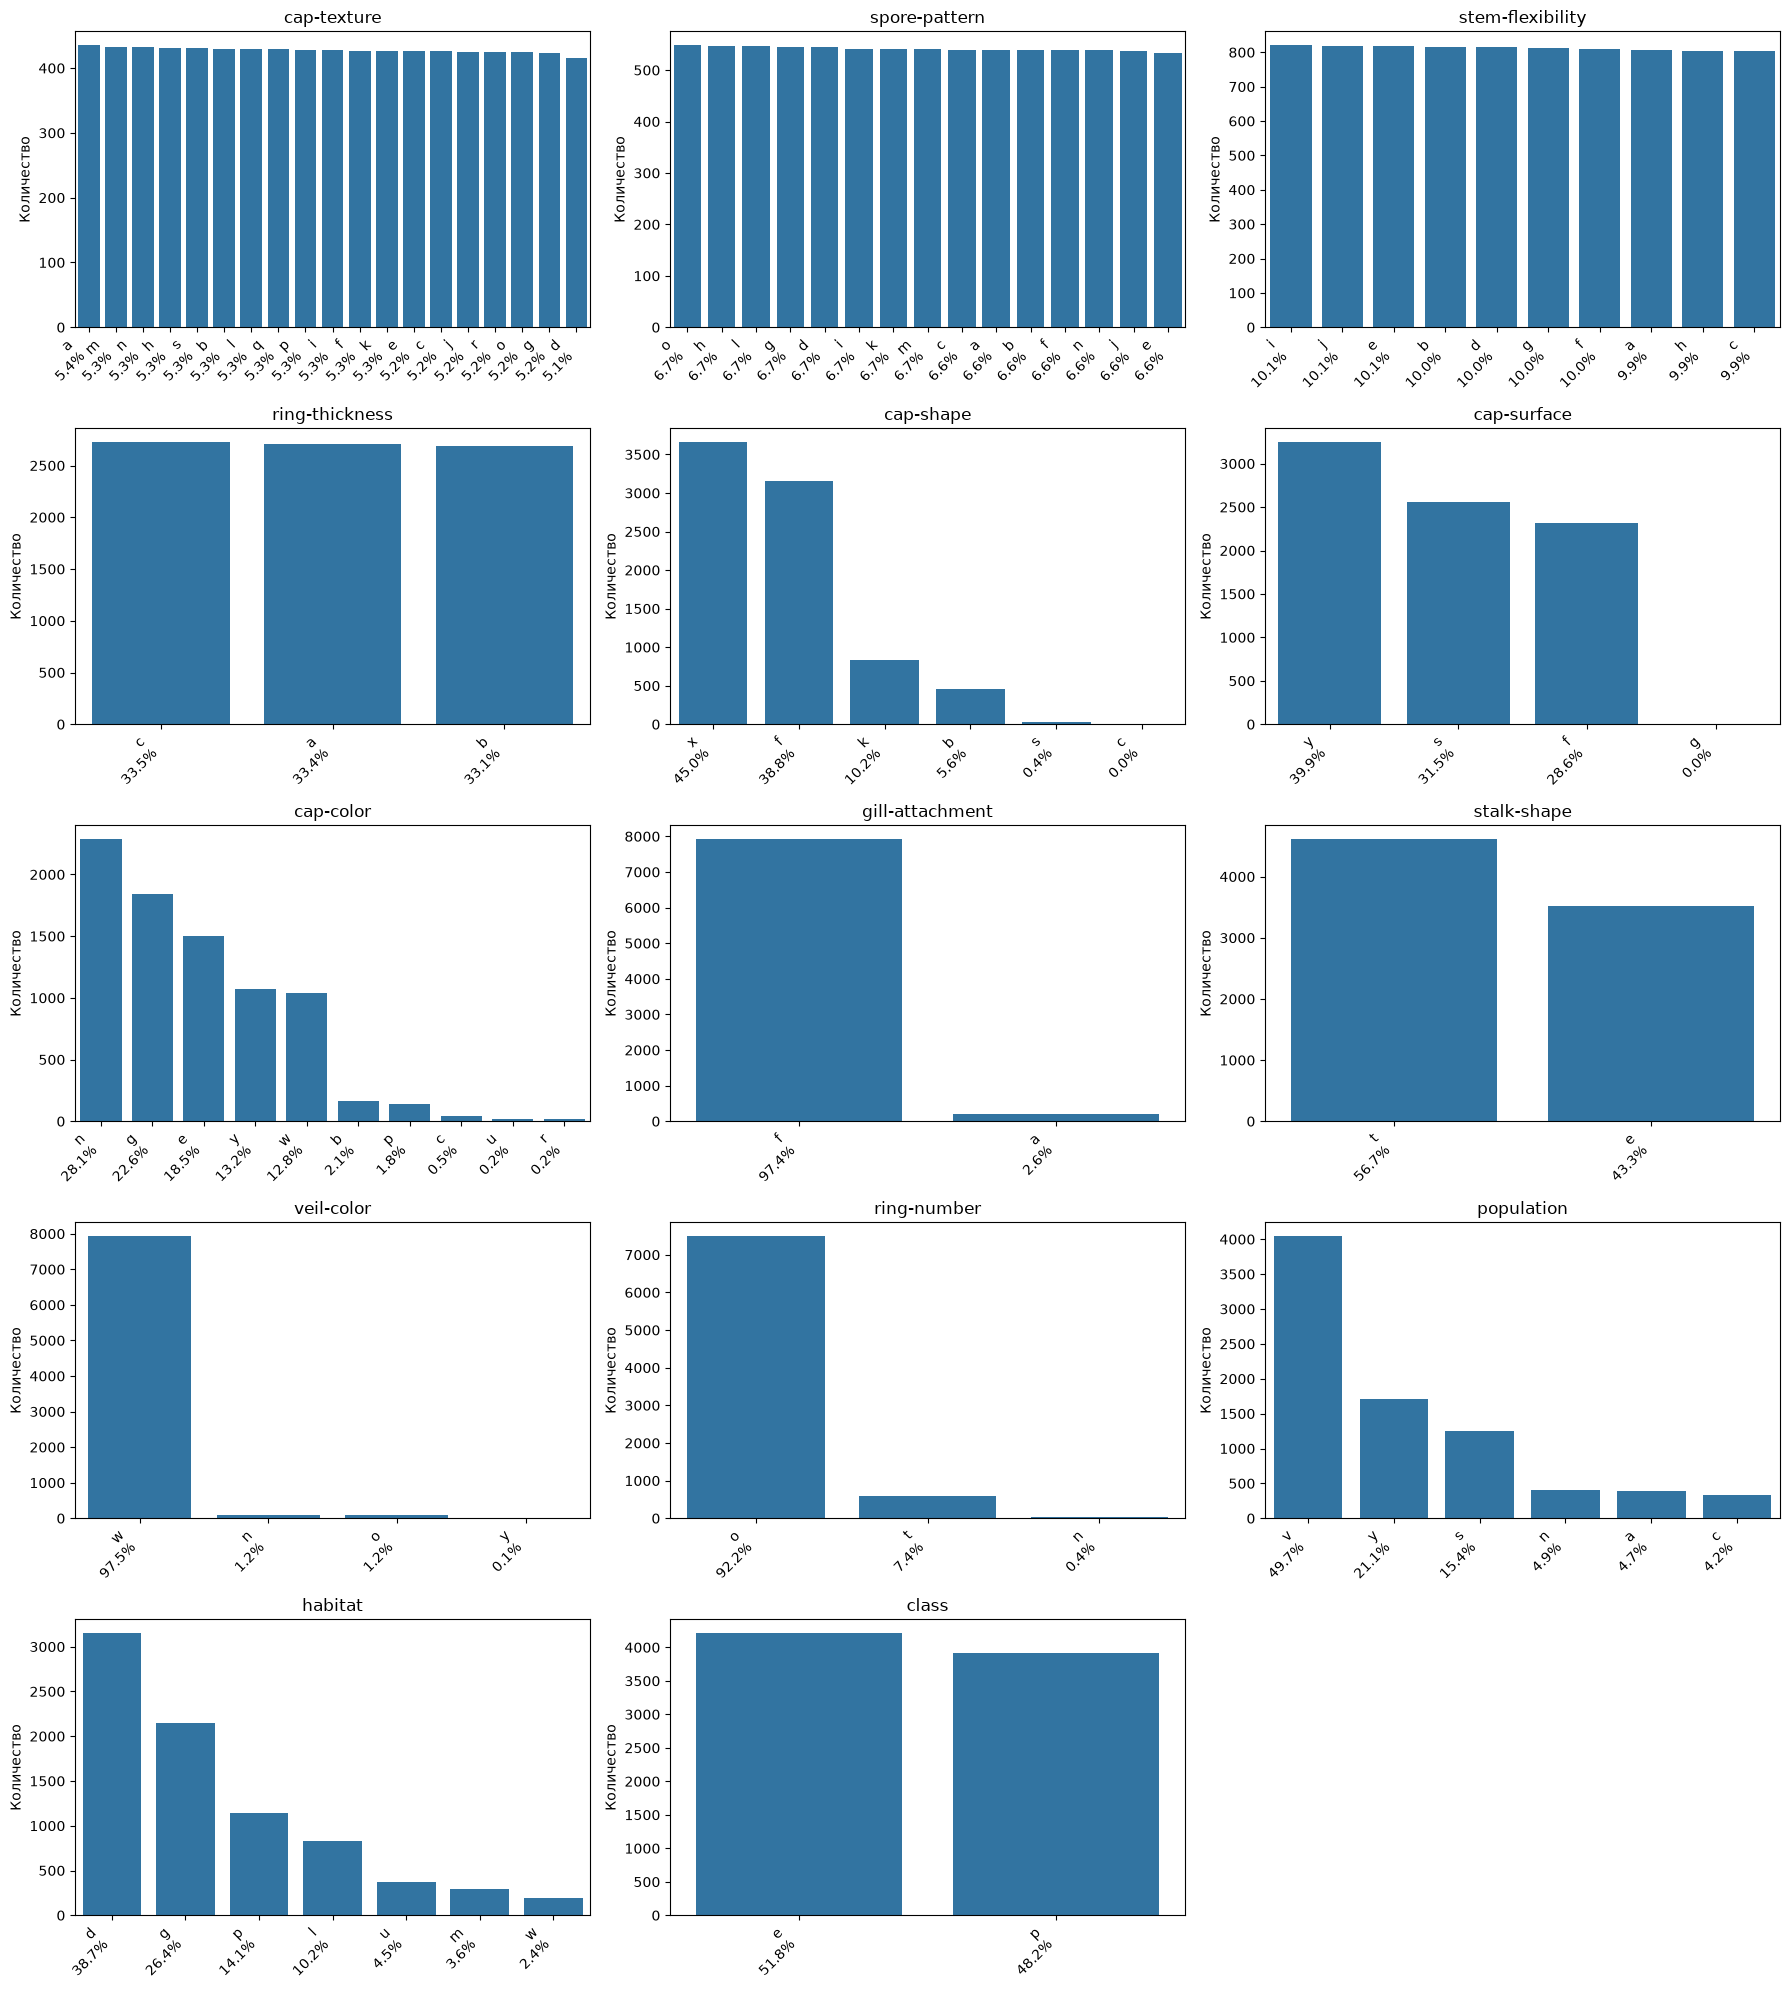

In [17]:
features = [column for column in df.columns]

n_cols = 3
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

for i, column in enumerate(features):
    # Считаем количество и проценты для каждой категории
    counts = df[column].value_counts()
    percentages = counts / counts.sum() * 100

    # Задаём единый порядок для столбцов и подписей
    order = counts.index

    sns.countplot(data=df, x=column, order=order, ax=axes[i])

    axes[i].set_title(column)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Количество')

    # Под каждой категорией показываем её долю
    labels = [
        f'{category}\n{percentages[category]:.1f}%'
        for category in order
    ]
    axes[i].set_xticks(range(len(order)))
    axes[i].set_xticklabels(labels, rotation=45, ha='right')

# Скрываем неиспользованные ячейки
for ax in axes[len(features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

В ходе исследования категориальных признаков обнаружено одно значение ? в столбце ring-number. Оно заменено на NaN, а затем заполнено отдельной категорией missing.

Признак veil-type содержит только одно уникальное значение и не помогает различать объекты, поэтому он удалён.

В некоторых признаках обнаружены редкие категории, в том числе c в cap-shape, g в cap-surface, y в veil-color и n в ring-number. Эти значения предусмотрены описанием данных, поэтому на данном этапе они сохранены: редкость сама по себе не означает ошибку или неинформативность.

Классы распределены почти равномерно: около 51,8% съедобных и 48,2% ядовитых грибов. Существенного дисбаланса классов не выявлено.

## 3. Подготовка данных

Разделим данные со стратификацией в пропорции 80/10/10. Для sklearn используем One-Hot Encoding, обученный на train; для CatBoost сохраним исходные категории. Целевая переменная: e = 0, p = 1.

In [18]:
df['ring-number'] = df['ring-number'].fillna('missing')

In [19]:
X = df.drop(columns=['class'])
y = df['class']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print('Train:', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Test:', X_test.shape, y_test.shape)

Train: (6499, 13) (6499,)
Validation: (812, 13) (812,)
Test: (813, 13) (813,)


In [20]:
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

In [21]:
X_train_array = encoder.fit_transform(X_train)
X_val_array = encoder.transform(X_val)
X_test_array = encoder.transform(X_test)

In [22]:
columns = encoder.get_feature_names_out()

X_train_encoded = pd.DataFrame(
    X_train_array,
    columns=columns,
    index=X_train.index
)

X_val_encoded = pd.DataFrame(
    X_val_array,
    columns=columns,
    index=X_val.index
)

X_test_encoded = pd.DataFrame(
    X_test_array,
    columns=columns,
    index=X_test.index
)

In [23]:
class_mapping = {'e': 0, 'p': 1}

y_train_encoded = y_train.map(class_mapping)
y_val_encoded = y_val.map(class_mapping)
y_test_encoded = y_test.map(class_mapping)

In [24]:
for name, features, target in [
    ('Train', X_train_encoded, y_train_encoded),
    ('Validation', X_val_encoded, y_val_encoded),
    ('Test', X_test_encoded, y_test_encoded)
]:
    assert features.index.equals(target.index)
    assert features.columns.equals(X_train_encoded.columns)
    assert not features.isna().any().any() and not target.isna().any()
    print(name, features.shape, target.shape)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
print('Пропусков нет, строки и столбцы согласованы, выборки не пересекаются.')

Train (6499, 91) (6499,)
Validation (812, 91) (812,)
Test (813, 91) (813,)
Пропусков нет, строки и столбцы согласованы, выборки не пересекаются.


**Вывод:** Данные разделены со стратификацией на обучающую, валидационную и тестовую выборки в соотношении 80/10/10 с random_state=42. Пропуск в признаке ring-number заполнен отдельной категорией missing; неинформативный признак veil-type удалён ранее.

Для категориальных признаков выбран One-Hot Encoding: он представляет категории отдельными бинарными столбцами, не задавая между ними искусственного порядка. Кодировщик обучен только на тренировочной выборке и применён к остальным; неизвестные категории обрабатываются без ошибки. После преобразования получены датафреймы с одинаковыми понятными названиями 91 столбца и сохранёнными индексами.

Целевая переменная закодирована: e — 0, p — 1. Проверка показала, что пропусков в закодированных признаках и целевой переменной нет; данные готовы к обучению модели.

## 4. Метрики

Приоритет — обнаружение ядовитых грибов. Помимо Recall оцениваем Precision, Accuracy и абсолютное число ошибок каждого вида.

In [25]:
def evaluate_model(model, X, y):
    y_pred = model.predict(X).ravel()
    print(f"Recall ядовитых: {recall_score(y, y_pred, pos_label=1, zero_division=0)}")
    print(f"Precision ядовитых: {precision_score(y, y_pred, pos_label=1, zero_division=0)}")
    print(f"Accuracy: {accuracy_score(y, y_pred)}")

    print(f"Confusion Matrix: {confusion_matrix(y, y_pred, labels=[0, 1])}")

**Вывод:** Основная метрика сравнения моделей — Recall ядовитого класса: важно обнаружить как можно больше ядовитых грибов и не принять их за съедобные. Дополнительно используем Precision, чтобы оценить долю ошибочно отбракованных съедобных грибов среди предсказаний «ядовитый». Для презентации бизнесу также покажем матрицу ошибок с количеством ошибок каждого вида и Accuracy как общий показатель качества.

## 5. Модели и оценка качества

Сначала обучим базовый GradientBoostingClassifier, затем сравним модели с подбором параметров и исследуем пороги классификации.

### Базовая модель без подбора гиперпараметров

Обучаем базовый GradientBoostingClassifier со стандартными гиперпараметрами и random_state=42. Оцениваем train и test.

In [26]:
baseline_gb = GradientBoostingClassifier(random_state=42)
baseline_gb.fit(X_train_encoded, y_train_encoded)
print('Базовая модель — train:')
evaluate_model(baseline_gb, X_train_encoded, y_train_encoded)
print('Базовая модель — test:')
evaluate_model(baseline_gb, X_test_encoded, y_test_encoded)

Базовая модель — train:
Recall ядовитых: 0.9275454835620811
Precision ядовитых: 0.9478147423352903
Accuracy: 0.9404523772888137
Confusion Matrix: [[3206  160]
 [ 227 2906]]
Базовая модель — test:
Recall ядовитых: 0.9107142857142857
Precision ядовитых: 0.9394736842105263
Accuracy: 0.9286592865928659
Confusion Matrix: [[398  23]
 [ 35 357]]


### Дополнительный эксперимент: подбор и сравнение моделей

Далее сравниваем гиперпараметры по кросс-валидации внутри train. Для CatBoost дополнительно используем validation для ранней остановки. Эти эксперименты расширяют сравнение базовых моделей.

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [28]:
pipeline = Pipeline([
    ('encoder', encoder),
    ('model', GradientBoostingClassifier(random_state=42))
])

In [29]:
param_grid = {
    'model__n_estimators': [100, 300],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [2, 3],
}

In [30]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [31]:
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='recall',
    cv=cv,
    refit=True,
    verbose=1,
    n_jobs=-1
)

In [32]:
grid_search.fit(X_train, y_train_encoded)

print('Лучшие параметры:', grid_search.best_params_)
print('Средний Recall на CV:', grid_search.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


Лучшие параметры: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 300}
Средний Recall на CV: 0.9291417623349689


In [33]:
best_gb_model = grid_search.best_estimator_

print('Train:')
evaluate_model(best_gb_model, X_train, y_train_encoded)

print('\nValidation:')
evaluate_model(best_gb_model, X_val, y_val_encoded)

print('\nTest:')
evaluate_model(best_gb_model, X_test, y_test_encoded)

Train:
Recall ядовитых: 0.9323332269390361
Precision ядовитых: 0.9798725259979872
Accuracy: 0.9581474072934297
Confusion Matrix: [[3306   60]
 [ 212 2921]]

Validation:
Recall ядовитых: 0.9232736572890026
Precision ядовитых: 0.9809782608695652
Accuracy: 0.9544334975369458
Confusion Matrix: [[414   7]
 [ 30 361]]

Test:
Recall ядовитых: 0.9132653061224489
Precision ядовитых: 0.9754768392370572
Accuracy: 0.947109471094711
Confusion Matrix: [[412   9]
 [ 34 358]]


In [34]:
cat_features = X_train.columns.tolist()

In [35]:
model = CatBoostClassifier(
    cat_features=cat_features,
    iterations=5000,
    eval_metric='Logloss',
    custom_metric=['Recall', 'Precision', 'Accuracy'],
    random_seed=42,
    verbose=100
)

model.fit(
    X_train, 
    y_train_encoded,
    early_stopping_rounds=50,
    eval_set=(X_val, y_val_encoded),
    use_best_model=True
)

Learning rate set to 0.024982
0:	learn: 0.6487260	test: 0.6488096	best: 0.6488096 (0)	total: 64.4ms	remaining: 5m 22s


100:	learn: 0.1092933	test: 0.1048074	best: 0.1048074 (100)	total: 534ms	remaining: 25.9s


200:	learn: 0.0993436	test: 0.0971128	best: 0.0971128 (200)	total: 973ms	remaining: 23.2s


300:	learn: 0.0927408	test: 0.0921836	best: 0.0921836 (300)	total: 1.44s	remaining: 22.5s


400:	learn: 0.0856417	test: 0.0885001	best: 0.0884748 (385)	total: 2.13s	remaining: 24.4s


500:	learn: 0.0803200	test: 0.0862932	best: 0.0862932 (500)	total: 3.27s	remaining: 29.3s


... (2 outputs left out)

800:	learn: 0.0691547	test: 0.0829397	best: 0.0829397 (800)	total: 4.83s	remaining: 25.3s


900:	learn: 0.0658381	test: 0.0823413	best: 0.0823226 (891)	total: 5.4s	remaining: 24.6s


Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.08220408105
bestIteration = 921

Shrink model to first 922 iterations.


CatBoostClassifier(cat_features=['cap-texture', 'spore-pattern', 'stem-flexibility', 'ring-thickness', 'cap-shape', 'cap-surface', 'cap-color', 'gill-attachment', 'stalk-shape', 'veil-color', 'ring-number', 'population', 'habitat'], custom_metric=['Recall', 'Precision', 'Accuracy'], eval_metric='Logloss', iterations=5000, random_seed=42, verbose=100)

In [36]:
print('CatBoost — train:')
evaluate_model(model, X_train, y_train_encoded)

print('\nCatBoost — validation:')
evaluate_model(model, X_val, y_val_encoded)

print('\nCatBoost — test:')
evaluate_model(model, X_test, y_test_encoded)

CatBoost — train:
Recall ядовитых: 0.9342483242898181
Precision ядовитых: 0.9865183687226154
Accuracy: 0.9621480227727343
Confusion Matrix: [[3326   40]
 [ 206 2927]]

CatBoost — validation:
Recall ядовитых: 0.9309462915601023
Precision ядовитых: 0.9891304347826086
Accuracy: 0.9618226600985221
Confusion Matrix: [[417   4]
 [ 27 364]]

CatBoost — test:
Recall ядовитых: 0.9183673469387755
Precision ядовитых: 0.9809264305177112
Accuracy: 0.9520295202952029
Confusion Matrix: [[414   7]
 [ 32 360]]


In [37]:
# Модели для сравнения
models = {
    'Gradient Boosting': best_gb_model,
    'CatBoost': model
}

# Выборки для сравнения
datasets = {
    'Train': (X_train, y_train_encoded),
    'Validation': (X_val, y_val_encoded),
    'Test': (X_test, y_test_encoded)
}

results = []

for model_name, trained_model in models.items():
    for dataset_name, (X_data, y_true) in datasets.items():
        y_pred = trained_model.predict(X_data).ravel()

        # Строки — настоящие классы, столбцы — предсказанные
        matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])

        results.append({
            'Модель': model_name,
            'Выборка': dataset_name,
            'Recall ядовитых': recall_score(y_true, y_pred, pos_label=1),
            'Precision ядовитых': precision_score(y_true, y_pred, pos_label=1),
            'Accuracy': accuracy_score(y_true, y_pred),
            'Ядовитые пропущены': matrix[1, 0],
            'Съедобные отбракованы': matrix[0, 1]
        })

comparison = pd.DataFrame(results)
comparison.round(3)

,Модель,Выборка,Recall ядовитых,Precision ядовитых,Accuracy,Ядовитые пропущены,Съедобные отбракованы
0,Gradient Boosting,Train,0.932,0.980,0.958,212,60
1,Gradient Boosting,Validation,0.923,0.981,0.954,30,7
2,Gradient Boosting,Test,0.913,0.975,0.947,34,9
3,CatBoost,Train,0.934,0.987,0.962,206,40
4,CatBoost,Validation,0.931,0.989,0.962,27,4
5,CatBoost,Test,0.918,0.981,0.952,32,7


### Дополнительный эксперимент: кросс-валидация CatBoost и выбор порога

Параметры подбираем внутри train. Пороги сравниваем на validation; снижение порога увеличивает число предсказаний ядовитого класса.

In [38]:
cv_extra = StratifiedKFold(
    n_splits=5, 
    shuffle=True, 
    random_state=42
)

In [39]:
gb_extra_search = GridSearchCV(
    pipeline,
    {'model__n_estimators': [300], 'model__learning_rate': [0.1],
     'model__max_depth': [2, 3], 'model__subsample': [0.8, 1.0]},
    scoring='recall', cv=cv_extra, refit=True, n_jobs=-1, verbose=0
)
gb_extra_search.fit(X_train, y_train_encoded)
print('GB: параметры:', gb_extra_search.best_params_, 'Recall CV:', gb_extra_search.best_score_)

GB: параметры: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 300, 'model__subsample': 0.8} Recall CV: 0.9339289990879027


In [40]:
cat_extra_search = GridSearchCV(
    CatBoostClassifier(iterations=5000, random_seed=42, verbose=False, thread_count=1),
    {'depth': [4, 6], 'learning_rate': [0.03, 0.1]},
    scoring='recall', cv=cv_extra, refit=True, n_jobs=-1, verbose=0
)
cat_extra_search.fit(X_train, y_train_encoded, cat_features=cat_features)
print('CatBoost: параметры:', cat_extra_search.best_params_, 'Recall CV:', cat_extra_search.best_score_)

CatBoost: параметры: {'depth': 6, 'learning_rate': 0.1} Recall CV: 0.9422290841830107


In [41]:
threshold_rows = []
for name, fitted in {
    'GB прежний': best_gb_model, 'GB новый': gb_extra_search.best_estimator_,
    'CatBoost прежний': model, 'CatBoost новый': cat_extra_search.best_estimator_
}.items():
    positive_column = list(fitted.classes_).index(1)
    probabilities = fitted.predict_proba(X_val)[:, positive_column]
    for threshold in [0.50, 0.40, 0.30, 0.20]:
        predicted = (probabilities >= threshold).astype(int)
        matrix = confusion_matrix(y_val_encoded, predicted, labels=[0, 1])
        threshold_rows.append({
            'Модель': name, 'Порог': threshold,
            'Recall ядовитых': recall_score(y_val_encoded, predicted, pos_label=1),
            'Precision ядовитых': precision_score(y_val_encoded, predicted, pos_label=1, zero_division=0),
            'Accuracy': accuracy_score(y_val_encoded, predicted),
            'Пропущено ядовитых': matrix[1, 0],
            'Съедобные отбракованы': matrix[0, 1]
        })
threshold_comparison = pd.DataFrame(threshold_rows)
display(threshold_comparison.round(3))

,Модель,Порог,Recall ядовитых,Precision ядовитых,Accuracy,Пропущено ядовитых,Съедобные отбракованы
0,GB прежний,0.5,0.923,0.981,0.954,30,7
1,GB прежний,0.4,0.964,0.938,0.952,14,25
2,GB прежний,0.3,0.985,0.893,0.936,6,46
3,GB прежний,0.2,0.997,0.867,0.925,1,60
4,GB новый,0.5,0.926,0.976,0.953,29,9
5,GB новый,0.4,0.964,0.945,0.956,14,22
6,GB новый,0.3,0.985,0.900,0.940,6,43
7,GB новый,0.2,0.997,0.869,0.926,1,59
8,CatBoost прежний,0.5,0.931,0.989,0.962,27,4
9,CatBoost прежний,0.4,0.946,0.976,0.963,21,9


**Вывод:** Базовый GradientBoostingClassifier со стандартными гиперпараметрами получил на train Recall 92,8% и Accuracy 94,0%, на test — Recall 91,1%, Precision 93,9% и Accuracy 92,9%. Разрыв Recall между train и test небольшой; выраженного переобучения по этой метрике не наблюдается.

В дополнительном сравнении бустинг с подбором параметров получил на test Recall 91,3%, Precision 97,5% и Accuracy 94,7%. Для CatBoost показатели составили 91,8%, 98,1% и 95,2%. CatBoost пропустил 32 ядовитых гриба из 392, классический бустинг — 34. Преимущество CatBoost на этом разбиении небольшое. Recall на train составляет 93,2% для классического бустинга и 93,4% для CatBoost.

Дополнительно сравнили настройки обеих моделей с кросс-валидацией и разные пороги на validation. Снижение порога увеличивает число обнаруженных ядовитых грибов, но также увеличивает количество съедобных грибов, ошибочно признанных ядовитыми. Конкретные результаты приведены в таблице порогов; порог 0,2 на test в этой работе не проверялся. Приоритетом остаётся Recall ядовитого класса с учётом Precision и количества ошибок каждого вида.

## 6. Интерпретация CatBoost

Исследуем важность исходных признаков в модели CatBoost с ранней остановкой.

In [42]:
importance = pd.DataFrame({
    'Признак': model.feature_names_,
    'Важность': model.feature_importances_
})

importance = importance.sort_values('Важность', ascending=False)

importance

,Признак,Важность
8,stalk-shape,27.001261
11,population,20.697538
12,habitat,16.418927
5,cap-surface,11.082994
6,cap-color,9.836719
4,cap-shape,3.854524
9,veil-color,2.892762
10,ring-number,2.544257
0,cap-texture,1.835506
2,stem-flexibility,1.422228


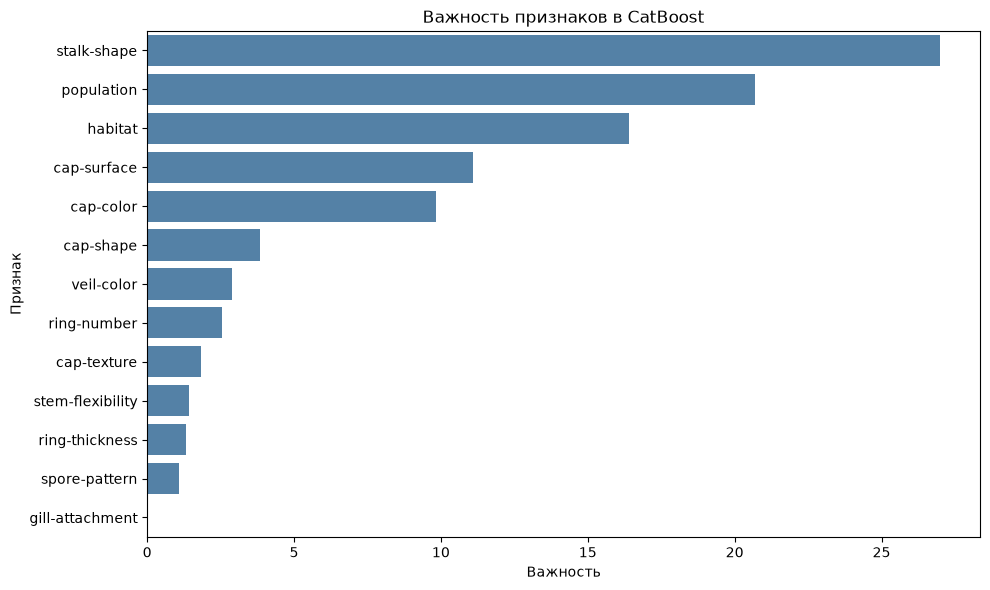

In [43]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Важность',
    y='Признак',
    color='steelblue'
)

plt.title('Важность признаков в CatBoost')
plt.xlabel('Важность')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

**Вывод:** Наиболее важными для CatBoost оказались форма ножки (stalk-shape), тип популяции (population) и среда обитания (habitat). Также заметный вклад внесли поверхность и цвет шляпки. Признак gill-attachment получил наименьшую важность, близкую к нулю. Эти оценки показывают, какие признаки использует обученная модель, но не устанавливают причин ядовитости грибов.